In [1]:

!pip install -q pandas numpy matplotlib seaborn
!pip install -q youtube-comment-downloader
!pip install -q Sastrawi nltk scikit-learn

print("Instalasi library berhasil!")


Instalasi library berhasil!


In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from youtube_comment_downloader import (
    YoutubeCommentDownloader,
    SORT_BY_RECENT
)

import re
import string
import nltk

print("Semua library berhasil dipanggil!")


Semua library berhasil dipanggil!


In [3]:

from youtube_comment_downloader import YoutubeCommentDownloader, SORT_BY_RECENT
import pandas as pd

# Membuat objek downloader
downloader = YoutubeCommentDownloader()

# Menyiapkan tempat penyimpanan komentar
data_komentar = []

print("Persiapan scraping berhasil!")


Persiapan scraping berhasil!


In [4]:

# Daftar sumber video YouTube
video_urls = [
    "https://www.youtube.com/watch?v=cDDyoC4Sqqk",
    "https://www.youtube.com/watch?v=2lBL3f-BlhI"
]

# Target maksimal komentar per video
max_comments = 250

# Menampung komentar
data_komentar = []

for url in video_urls:

    print("\nMengambil komentar dari:", url)

    try:
        hasil = downloader.get_comments_from_url(
            url,
            sort_by=SORT_BY_RECENT
        )

        jumlah = 0

        for komentar in hasil:

            teks = komentar.get("text", "").strip()

            if teks:

                data_komentar.append({
                    "komentar": teks,
                    "waktu": komentar.get("time", ""),
                    "jumlah_like": komentar.get("votes", ""),
                    "sumber_video": url
                })

                jumlah += 1

            if jumlah >= max_comments:
                break

        print("Komentar berhasil diambil:", jumlah)

    except Exception as e:
        print("Terjadi kesalahan:", e)

# Membuat dataset
df = pd.DataFrame(data_komentar)

# Menghapus komentar duplikat
if not df.empty:

    df = df.drop_duplicates(
        subset=["komentar"]
    ).reset_index(drop=True)

    # Menyimpan dataset
    df.to_csv(
        "dataset_mentah_timnas.csv",
        index=False,
        encoding="utf-8-sig"
    )

    print("\n===== HASIL SCRAPING =====")
    print("Total komentar:", len(df))

    display(df.head(10))

else:
    print("Belum ada komentar yang berhasil diambil.")



Mengambil komentar dari: https://www.youtube.com/watch?v=cDDyoC4Sqqk
Komentar berhasil diambil: 250

Mengambil komentar dari: https://www.youtube.com/watch?v=2lBL3f-BlhI
Komentar berhasil diambil: 97

===== HASIL SCRAPING =====
Total komentar: 342


,komentar,waktu,jumlah_like,sumber_video
0,"Komentator macan pukik,",1 month ago,1,https://www.youtube.com/watch?v=cDDyoC4Sqqk
1,buat yg hujat JH setelah game 10 orang lawan M...,1 month ago (edited),0,https://www.youtube.com/watch?v=cDDyoC4Sqqk
2,JH vs pringkat FiFA 100 keatas :\n1.Indonesia ...,2 months ago,1,https://www.youtube.com/watch?v=cDDyoC4Sqqk
3,"‎Pemain karakter seperti Ole romeny, Jay idzes...",3 months ago,0,https://www.youtube.com/watch?v=cDDyoC4Sqqk
4,kenapa gal main seperti ini pas aff,3 months ago,0,https://www.youtube.com/watch?v=cDDyoC4Sqqk
5,Lagi sedih liat aff kalah sama Vietnam 3:0. Ke...,3 months ago,0,https://www.youtube.com/watch?v=cDDyoC4Sqqk
6,"Saya puasa pemain Indonesia, ketikan di bawa s...",4 months ago,0,https://www.youtube.com/watch?v=cDDyoC4Sqqk
7,tanpa suara komentator lebih profesional min,4 months ago,0,https://www.youtube.com/watch?v=cDDyoC4Sqqk
8,suporter sejati itu ngasih kritik itu bagus ja...,4 months ago,0,https://www.youtube.com/watch?v=cDDyoC4Sqqk
9,This is the Mozambique second team you played,4 months ago,0,https://www.youtube.com/watch?v=cDDyoC4Sqqk


In [5]:

print("Jumlah dataset:", len(df))

if len(df) >= 100:
    print("BERHASIL: Dataset memenuhi syarat UTS!")
else:
    print("Dataset belum mencapai 100 komentar.")

display(df.head(20))


Jumlah dataset: 342
BERHASIL: Dataset memenuhi syarat UTS!


,komentar,waktu,jumlah_like,sumber_video
0,"Komentator macan pukik,",1 month ago,1,https://www.youtube.com/watch?v=cDDyoC4Sqqk
1,buat yg hujat JH setelah game 10 orang lawan M...,1 month ago (edited),0,https://www.youtube.com/watch?v=cDDyoC4Sqqk
2,JH vs pringkat FiFA 100 keatas :\n1.Indonesia ...,2 months ago,1,https://www.youtube.com/watch?v=cDDyoC4Sqqk
3,"‎Pemain karakter seperti Ole romeny, Jay idzes...",3 months ago,0,https://www.youtube.com/watch?v=cDDyoC4Sqqk
4,kenapa gal main seperti ini pas aff,3 months ago,0,https://www.youtube.com/watch?v=cDDyoC4Sqqk
5,Lagi sedih liat aff kalah sama Vietnam 3:0. Ke...,3 months ago,0,https://www.youtube.com/watch?v=cDDyoC4Sqqk
6,"Saya puasa pemain Indonesia, ketikan di bawa s...",4 months ago,0,https://www.youtube.com/watch?v=cDDyoC4Sqqk
7,tanpa suara komentator lebih profesional min,4 months ago,0,https://www.youtube.com/watch?v=cDDyoC4Sqqk
8,suporter sejati itu ngasih kritik itu bagus ja...,4 months ago,0,https://www.youtube.com/watch?v=cDDyoC4Sqqk
9,This is the Mozambique second team you played,4 months ago,0,https://www.youtube.com/watch?v=cDDyoC4Sqqk


In [6]:

# Menyimpan salinan dataset asli
df_mentah = df.copy()

df_mentah.to_csv(
    "dataset_mentah_timnas.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Dataset mentah berhasil disimpan!")
print("Jumlah data awal:", len(df_mentah))


Dataset mentah berhasil disimpan!
Jumlah data awal: 342


In [7]:

import re
import pandas as pd

# Fungsi untuk membersihkan komentar
def cleaning_text(teks):

    # Mengubah teks menjadi string
    teks = str(teks)

    # Mengubah huruf menjadi kecil
    teks = teks.lower()

    # Menghapus URL
    teks = re.sub(r'http\S+|www\S+', '', teks)

    # Menghapus tag HTML
    teks = re.sub(r'<.*?>', '', teks)

    # Menghapus username atau mention
    teks = re.sub(r'@\w+', '', teks)

    # Menghapus tanda baca dan angka
    teks = re.sub(r'[^a-zA-Z\s]', ' ', teks)

    # Menghapus spasi berlebihan
    teks = re.sub(r'\s+', ' ', teks).strip()

    return teks


# Membuat salinan dataset
df_clean = df_mentah.copy()

# Menghapus data kosong
df_clean = df_clean.dropna(subset=['komentar'])

# Menghapus data duplikat
df_clean = df_clean.drop_duplicates(
    subset=['komentar']
)

# Membersihkan komentar
df_clean['komentar_bersih'] = (
    df_clean['komentar'].apply(cleaning_text)
)

# Menghapus komentar yang kosong setelah cleaning
df_clean = df_clean[
    df_clean['komentar_bersih'].str.strip() != ''
].copy()

# Menghapus index lama
df_clean = df_clean.reset_index(drop=True)

print("PROSES CLEANING SELESAI")
print("Jumlah data awal:", len(df_mentah))
print("Jumlah data setelah cleaning:", len(df_clean))

display(df_clean[['komentar', 'komentar_bersih']].head(15))


PROSES CLEANING SELESAI
Jumlah data awal: 342
Jumlah data setelah cleaning: 336


,komentar,komentar_bersih
0,"Komentator macan pukik,",komentator macan pukik
1,buat yg hujat JH setelah game 10 orang lawan M...,buat yg hujat jh setelah game orang lawan mala...
2,JH vs pringkat FiFA 100 keatas :\n1.Indonesia ...,jh vs pringkat fifa keatas indonesia bulgaria ...
3,"‎Pemain karakter seperti Ole romeny, Jay idzes...",pemain karakter seperti ole romeny jay idzes c...
4,kenapa gal main seperti ini pas aff,kenapa gal main seperti ini pas aff
5,Lagi sedih liat aff kalah sama Vietnam 3:0. Ke...,lagi sedih liat aff kalah sama vietnam kesini ...
6,"Saya puasa pemain Indonesia, ketikan di bawa s...",saya puasa pemain indonesia ketikan di bawa sa...
7,tanpa suara komentator lebih profesional min,tanpa suara komentator lebih profesional min
8,suporter sejati itu ngasih kritik itu bagus ja...,suporter sejati itu ngasih kritik itu bagus ja...
9,This is the Mozambique second team you played,this is the mozambique second team you played


In [8]:

print("===== HASIL DATA CLEANING =====")

print("Jumlah data sebelum cleaning:", len(df_mentah))
print("Jumlah data sesudah cleaning:", len(df_clean))

print("\nContoh komentar sebelum dan sesudah cleaning:")

for i in range(min(10, len(df_clean))):

    print("\nSebelum:")
    print(df_clean['komentar'].iloc[i])

    print("Sesudah:")
    print(df_clean['komentar_bersih'].iloc[i])

print("\nJumlah data kosong:")
print(df_clean['komentar_bersih'].isnull().sum())


===== HASIL DATA CLEANING =====
Jumlah data sebelum cleaning: 342
Jumlah data sesudah cleaning: 336

Contoh komentar sebelum dan sesudah cleaning:

Sebelum:
Komentator macan pukik,
Sesudah:
komentator macan pukik

Sebelum:
buat yg hujat JH setelah game 10 orang lawan Malaysia mgkn jg harus liat match ini, match lawan Oman, Bulgaria, Saint Kitt and Nevis
Sesudah:
buat yg hujat jh setelah game orang lawan malaysia mgkn jg harus liat match ini match lawan oman bulgaria saint kitt and nevis

Sebelum:
JH vs pringkat FiFA 100 keatas :
1.Indonesia 0-1 Bulgaria 
2.Indonesia 3-0 Oman
3.Indonesia 1-0 Mozambik 
4.Indonesia 0-3 Vietnam
Sesudah:
jh vs pringkat fifa keatas indonesia bulgaria indonesia oman indonesia mozambik indonesia vietnam

Sebelum:
‎Pemain karakter seperti Ole romeny, Jay idzes, Calvin verdonk, Thom hate, Diks, joy pelopesi, Paes, Emil audero, sandy walsh, Eliano, milliano Jonathan, syne patti nama, ragnard oratmanguen, Justin hubner, ivar janner, nathan Tjoe-aon, mitcher Bakkar

In [9]:

df_clean.to_csv(
    "dataset_cleaning_timnas.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Dataset hasil cleaning berhasil disimpan!")

from google.colab import files

files.download("dataset_cleaning_timnas.csv")


Dataset hasil cleaning berhasil disimpan!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [10]:

import nltk
import re
import pandas as pd

from nltk.corpus import stopwords
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory

# Download stopwords
nltk.download('stopwords')

# Mengambil stopwords bahasa Indonesia
stop_words = set(stopwords.words('indonesian'))

# Membuat stemmer bahasa Indonesia
factory = StemmerFactory()
stemmer = factory.create_stemmer()

print("Library preprocessing berhasil disiapkan!")


Library preprocessing berhasil disiapkan!


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


In [11]:

def tokenizing(teks):

    # Memisahkan kalimat berdasarkan spasi
    token = teks.split()

    return token


# Contoh tokenizing
contoh = df_clean['komentar_bersih'].iloc[0]

print("Kalimat:")
print(contoh)

print("\nHasil tokenizing:")
print(tokenizing(contoh))


Kalimat:
komentator macan pukik

Hasil tokenizing:
['komentator', 'macan', 'pukik']


In [12]:

# Kata negasi yang harus dipertahankan
kata_penting = {
    'tidak', 'bukan', 'belum', 'kurang',
    'jangan', 'tanpa', 'gagal'
}

# Menghapus kata umum
def stopword_removal(tokens):

    hasil = [
        kata for kata in tokens
        if kata not in stop_words or kata in kata_penting
    ]

    return hasil


# Contoh
hasil_token = tokenizing(contoh)

hasil_stopword = stopword_removal(hasil_token)

print("Sebelum stopword removal:")
print(hasil_token)

print("\nSesudah stopword removal:")
print(hasil_stopword)


Sebelum stopword removal:
['komentator', 'macan', 'pukik']

Sesudah stopword removal:
['komentator', 'macan', 'pukik']


In [13]:

def stemming(tokens):

    hasil = [
        stemmer.stem(kata)
        for kata in tokens
    ]

    return hasil


# Contoh stemming
hasil_stemming = stemming(hasil_stopword)

print("Sebelum stemming:")
print(hasil_stopword)

print("\nSesudah stemming:")
print(hasil_stemming)


Sebelum stemming:
['komentator', 'macan', 'pukik']

Sesudah stemming:
['komentator', 'macan', 'pukik']


In [14]:

# Fungsi preprocessing lengkap
def preprocessing(teks):

    # Tokenizing
    tokens = tokenizing(teks)

    # Stopword removal
    tokens = stopword_removal(tokens)

    # Stemming
    tokens = stemming(tokens)

    # Menggabungkan kembali kata
    return ' '.join(tokens)


# Menerapkan preprocessing ke seluruh data
df_clean['hasil_preprocessing'] = (
    df_clean['komentar_bersih'].apply(preprocessing)
)

print("PROSES PREPROCESSING SELESAI!")

display(
    df_clean[
        ['komentar_bersih', 'hasil_preprocessing']
    ].head(15)
)


PROSES PREPROCESSING SELESAI!


,komentar_bersih,hasil_preprocessing
0,komentator macan pukik,komentator macan pukik
1,buat yg hujat jh setelah game orang lawan mala...,yg hujat jh game orang lawan malaysia mgkn jg ...
2,jh vs pringkat fifa keatas indonesia bulgaria ...,jh vs pringkat fifa atas indonesia bulgaria in...
3,pemain karakter seperti ole romeny jay idzes c...,main karakter ole romeny jay idzes calvin verd...
4,kenapa gal main seperti ini pas aff,gal main pas aff
5,lagi sedih liat aff kalah sama vietnam kesini ...,sedih liat aff kalah vietnam kesini hibur
6,saya puasa pemain indonesia ketikan di bawa sa...,puasa main indonesia keti bawa latih
7,tanpa suara komentator lebih profesional min,tanpa suara komentator profesional min
8,suporter sejati itu ngasih kritik itu bagus ja...,suporter sejati ngasih kritik bagus jangan men...
9,this is the mozambique second team you played,this is the mozambique second team you played


In [15]:

df_clean.to_csv(
    "dataset_preprocessing_timnas.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Dataset preprocessing berhasil disimpan!")

from google.colab import files

files.download("dataset_preprocessing_timnas.csv")


Dataset preprocessing berhasil disimpan!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [16]:

# Membuat salinan dataset preprocessing
df_label = df_clean.copy()

# Menambahkan kolom label kosong
df_label['sentimen'] = ''

# Memilih kolom yang diperlukan
df_label = df_label[
    ['komentar', 'hasil_preprocessing', 'sentimen']
]

# Menyimpan file untuk pelabelan manual
df_label.to_csv(
    'dataset_pelabelan_timnas.csv',
    index=False,
    encoding='utf-8-sig'
)

print("File pelabelan berhasil dibuat!")
print("Jumlah komentar:", len(df_label))

display(df_label.head(10))

# Download file
from google.colab import files
files.download('dataset_pelabelan_timnas.csv')


File pelabelan berhasil dibuat!
Jumlah komentar: 336


,komentar,hasil_preprocessing,sentimen
0,"Komentator macan pukik,",komentator macan pukik,
1,buat yg hujat JH setelah game 10 orang lawan M...,yg hujat jh game orang lawan malaysia mgkn jg ...,
2,JH vs pringkat FiFA 100 keatas :\n1.Indonesia ...,jh vs pringkat fifa atas indonesia bulgaria in...,
3,"‎Pemain karakter seperti Ole romeny, Jay idzes...",main karakter ole romeny jay idzes calvin verd...,
4,kenapa gal main seperti ini pas aff,gal main pas aff,
5,Lagi sedih liat aff kalah sama Vietnam 3:0. Ke...,sedih liat aff kalah vietnam kesini hibur,
6,"Saya puasa pemain Indonesia, ketikan di bawa s...",puasa main indonesia keti bawa latih,
7,tanpa suara komentator lebih profesional min,tanpa suara komentator profesional min,
8,suporter sejati itu ngasih kritik itu bagus ja...,suporter sejati ngasih kritik bagus jangan men...,
9,This is the Mozambique second team you played,this is the mozambique second team you played,


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

===== HASIL ANALISIS SENTIMEN =====
Total komentar: 336

Jumlah sentimen:
sentimen
netral     264
positif     59
negatif     13
Name: count, dtype: int64

Persentase sentimen:
sentimen
netral     78.57
positif    17.56
negatif     3.87
Name: proportion, dtype: float64

Contoh hasil analisis:


,komentar,hasil_preprocessing,skor_sentimen,sentimen
0,"Komentator macan pukik,",komentator macan pukik,0,netral
1,buat yg hujat JH setelah game 10 orang lawan M...,yg hujat jh game orang lawan malaysia mgkn jg ...,0,netral
2,JH vs pringkat FiFA 100 keatas :\n1.Indonesia ...,jh vs pringkat fifa atas indonesia bulgaria in...,0,netral
3,"‎Pemain karakter seperti Ole romeny, Jay idzes...",main karakter ole romeny jay idzes calvin verd...,0,netral
4,kenapa gal main seperti ini pas aff,gal main pas aff,0,netral
5,Lagi sedih liat aff kalah sama Vietnam 3:0. Ke...,sedih liat aff kalah vietnam kesini hibur,-2,negatif
6,"Saya puasa pemain Indonesia, ketikan di bawa s...",puasa main indonesia keti bawa latih,0,netral
7,tanpa suara komentator lebih profesional min,tanpa suara komentator profesional min,0,netral
8,suporter sejati itu ngasih kritik itu bagus ja...,suporter sejati ngasih kritik bagus jangan men...,2,positif
9,This is the Mozambique second team you played,this is the mozambique second team you played,0,netral


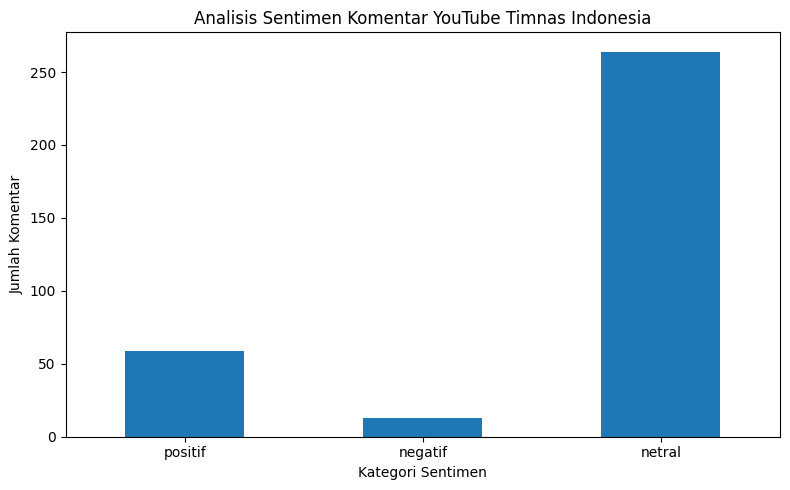


Hasil analisis berhasil disimpan!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [17]:

# ==========================================
# TAHAP 4: ANALISIS SENTIMEN TIMNAS INDONESIA
# METODE: LEXICON-BASED
# ==========================================

import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files

# Memastikan dataset tersedia
if 'df_clean' not in globals():
    raise ValueError("Dataset df_clean belum tersedia. Jalankan kembali tahap cleaning dan preprocessing.")

# Menggunakan hasil preprocessing
kolom_teks = 'hasil_preprocessing'

# Kamus kata sentimen positif
kata_positif = {
    'bagus', 'baik', 'hebat', 'mantap', 'bangga',
    'dukung', 'menang', 'juara', 'keren', 'solid',
    'unggul', 'terbaik', 'puas', 'semangat', 'cinta',
    'kuat', 'indah', 'sukses', 'lolos', 'berhasil',
    'cepat', 'tajam', 'gol', 'top', 'hebat'
}

# Kamus kata sentimen negatif
kata_negatif = {
    'buruk', 'jelek', 'kalah', 'kecewa', 'gagal',
    'parah', 'lambat', 'lemah', 'payah', 'hancur',
    'bodoh', 'tolol', 'malu', 'sedih', 'sulit',
    'kurang', 'blunder', 'pecat', 'ampas', 'frustrasi',
    'mengecewakan', 'kacau', 'ancur', 'error'
}

# Kata negasi
negasi = {'tidak', 'bukan', 'belum', 'kurang'}

# Fungsi menghitung sentimen
def analisis_sentimen(teks):
    tokens = str(teks).split()

    skor = 0

    for i, kata in enumerate(tokens):
        sebelumnya = tokens[i-1] if i > 0 else ''

        if kata in kata_positif:
            if sebelumnya in negasi:
                skor -= 1
            else:
                skor += 1

        elif kata in kata_negatif:
            if sebelumnya in negasi:
                skor += 1
            else:
                skor -= 1

    if skor > 0:
        label = 'positif'
    elif skor < 0:
        label = 'negatif'
    else:
        label = 'netral'

    return pd.Series([skor, label])


# Menerapkan analisis pada seluruh komentar
df_hasil = df_clean.copy()

df_hasil[['skor_sentimen', 'sentimen']] = (
    df_hasil[kolom_teks].apply(analisis_sentimen)
)

# Menghitung jumlah setiap sentimen
jumlah_sentimen = df_hasil['sentimen'].value_counts()

print("===== HASIL ANALISIS SENTIMEN =====")
print("Total komentar:", len(df_hasil))
print("\nJumlah sentimen:")
print(jumlah_sentimen)

# Menghitung persentase
persentase = (
    df_hasil['sentimen'].value_counts(normalize=True) * 100
)

print("\nPersentase sentimen:")
print(persentase.round(2))

# Menampilkan contoh hasil
print("\nContoh hasil analisis:")
display(
    df_hasil[
        ['komentar', 'hasil_preprocessing',
         'skor_sentimen', 'sentimen']
    ].head(15)
)

# Membuat grafik
urutan = ['positif', 'negatif', 'netral']
jumlah_grafik = (
    df_hasil['sentimen']
    .value_counts()
    .reindex(urutan, fill_value=0)
)

plt.figure(figsize=(8, 5))
jumlah_grafik.plot(kind='bar')
plt.title('Analisis Sentimen Komentar YouTube Timnas Indonesia')
plt.xlabel('Kategori Sentimen')
plt.ylabel('Jumlah Komentar')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Menyimpan hasil
df_hasil.to_csv(
    'hasil_analisis_sentimen_timnas.csv',
    index=False,
    encoding='utf-8-sig'
)

print("\nHasil analisis berhasil disimpan!")

# Download hasil
files.download('hasil_analisis_sentimen_timnas.csv')
